In [1]:
import starfile
from findingampa.utils.analysis import render_active_zonograms, calculate_probit, estimate_anisotropic_gaussian_for_probit, calculate_1q_p_value, render_active_zonograms, select_aunps
import pymeshlab
from pathlib import Path
from scipy.spatial import cKDTree
from matplotlib import pyplot as plt
import torch
import mrcfile
import numpy as np

In [2]:
tom = "20241211_HippWaffle_50"
aunp_data = starfile.read(f"/home/gouauxlab/andecath/test/{tom}/best_alignment/aunps/aunp_tm_BP.star")

In [11]:
amp_rank, amp_pro = calculate_probit(aunp_data["faTomo_gaussianFitAmplitude"].to_numpy()* -1)
pea_rank, pea_pro = calculate_probit(aunp_data["faTM_PeakScore"].to_numpy())

Dinv_, Uinv__ = estimate_anisotropic_gaussian_for_probit(amp_pro, pea_pro, None, False, False)
pval,neg_log_p1q_equ_pro_ = calculate_1q_p_value(amp_pro, pea_pro, Dinv_, Uinv__)

sel_aunps = aunp_data[aunp_data["faTomo_gaussianFitAmplitude"] < -5]
sel_aunps = sel_aunps[sel_aunps["faTomo_gaussianFitSigmaX"] < 1]
sel_aunps = sel_aunps[sel_aunps["faTM_PeakScore"] > 0.33]

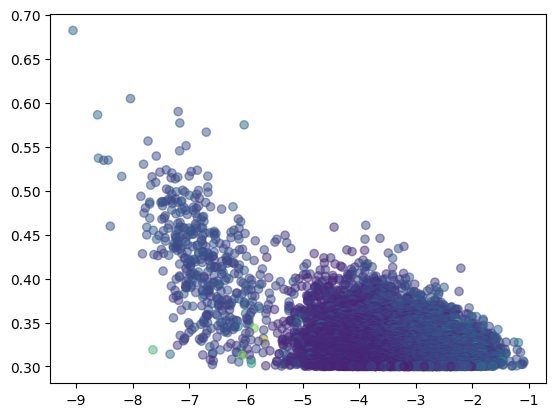

In [12]:
# Use interactive Backend
plt.close('all')
plt.switch_backend('agg')
%matplotlib inline
# Reseset plt
plt.clf()
plt.scatter(aunp_data["faTomo_gaussianFitAmplitude"].to_numpy(), aunp_data["faTM_PeakScore"].to_numpy(),c=aunp_data["faTomo_gaussianFitSigmaX"].to_numpy(), alpha=0.5)


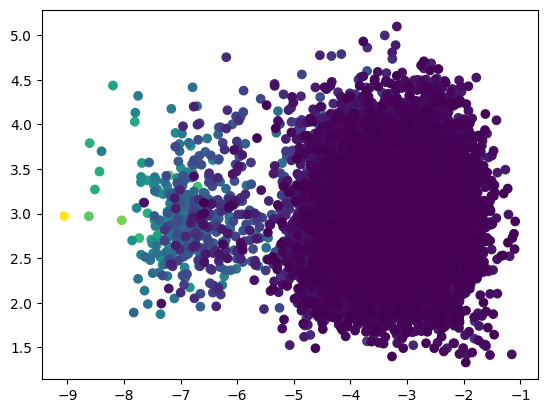

In [13]:
plt.scatter(aunp_data["faTomo_gaussianFitAmplitude"].to_numpy(), aunp_data["faTM_gaussianFitSigmaX"].to_numpy(), c=aunp_data["faTM_PeakScore"].to_numpy())

In [14]:
with mrcfile.open(f"/home/gouauxlab/andecath/test/{tom}/best_alignment/active_zonograms/active_zonogram_0.mrc", permissive=True) as mrc:
    res_ddw = torch.tensor(mrc.data.copy())

In [15]:
az_data = np.load(f"/home/gouauxlab/andecath/test/{tom}/best_alignment/active_zonograms/active_zonogram_0.npy" ,allow_pickle=True)

In [16]:
az_data

array({'cs': array([[ 0.64994186,  0.75998393, -0.        ],
       [ 0.29629809, -0.25339553, -0.92086815],
       [-0.699845  ,  0.59851076, -0.38987415]]), 'center': array([448.85297328, 520.10805259, 119.56955116]), 'objects': (0, 0)},
      dtype=object)

In [17]:
fig = render_active_zonograms((None,None,res_ddw))
selected_aunp_pos = sel_aunps[["faTM_PeakX", "faTM_PeakY", "faTM_PeakZ"]].values + sel_aunps[["faTomo_gaussianFitX", "faTomo_gaussianFitY", "faTomo_gaussianFitZ"]].values

selected_aunp_pos_transformed = (selected_aunp_pos - az_data.tolist()["center"]) @ az_data.tolist()["cs"].T
selected_aunp_pos_transformed += np.floor(np.array(res_ddw.shape)[[2,1,0]]/2)
selected_aunp_pos_transformed = selected_aunp_pos_transformed[np.all(selected_aunp_pos_transformed > 0, axis=1)]
selected_aunp_pos_transformed = selected_aunp_pos_transformed[np.all(selected_aunp_pos_transformed < np.array(res_ddw.shape)[[2,1,0]], axis=1)]
(axxy, axxz, axyz) = fig.get_axes()
axxy.scatter(selected_aunp_pos_transformed[:,0], selected_aunp_pos_transformed[:,1], s=1,c='r')
axxz.scatter(selected_aunp_pos_transformed[:,2], selected_aunp_pos_transformed[:,1], s=1,c='r')
axyz.scatter(selected_aunp_pos_transformed[:,0], selected_aunp_pos_transformed[:,2], s=1,c='r')


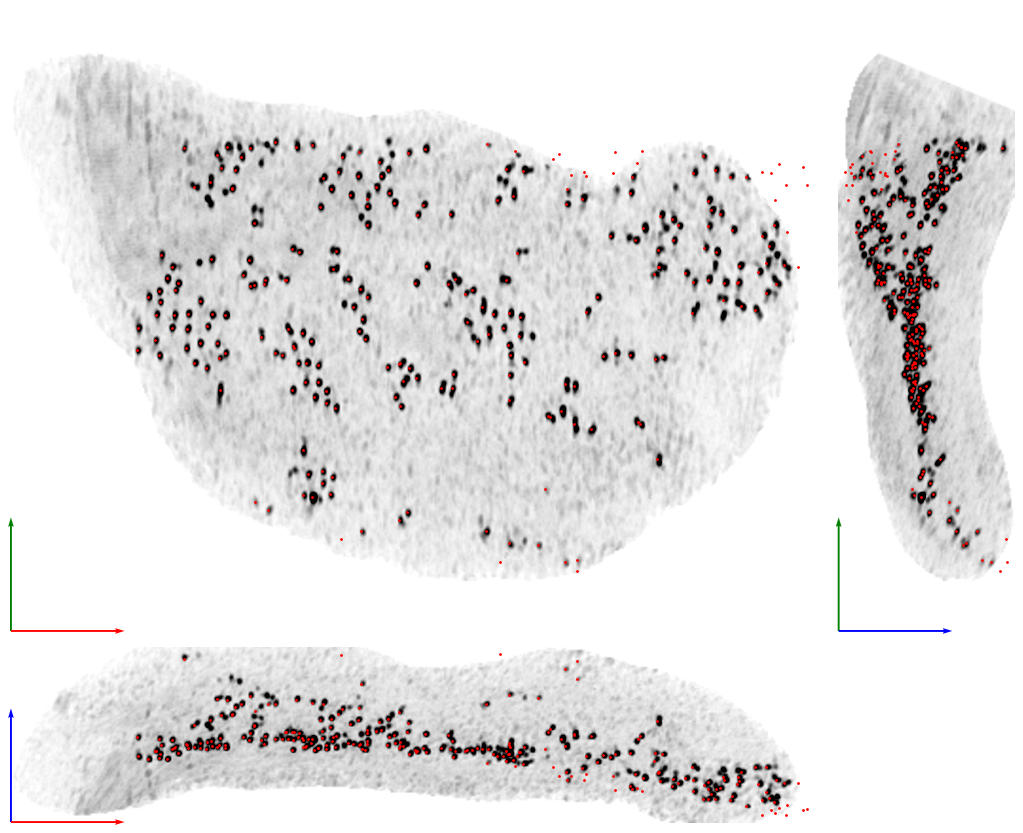

In [18]:
fig